# BÁO CÁO TOÀN DIỆN: PHÂN LOẠI ẢNH THỜI TRANG FASHIONMNIST BẰNG PYTORCH
## Quy trình Deep Learning chuẩn 21 bước — Khám phá dữ liệu, Huấn luyện, Đánh giá và Phân tích lỗi

---
### 📌 THÔNG TIN TỔNG QUAN
- **Đề tài:** Phân loại ảnh thời trang FashionMNIST (10 lớp) sử dụng Deep Learning (PyTorch).
- **Mục tiêu:** Áp dụng tư duy kỹ thuật Machine Learning / Deep Learning chuẩn mực gồm 21 bước; xây dựng pipeline tái lập được, kiểm chứng bằng thực nghiệm và trực quan hóa toàn diện.
- **Thư viện trực quan hóa chính:**
  1. `matplotlib.pyplot` (phiên bản `3.11.2`): Vẽ lưới ảnh mẫu (sample grid), biểu đồ lịch sử huấn luyện (loss/accuracy curves), phổ histogram pixel, biểu đồ cột F1-score và lưới phân tích sai số (error analysis grid).
  2. `seaborn` (phiên bản `0.13.2`): Vẽ ma trận nhầm lẫn (heatmap Confusion Matrix) cả dạng số lượng tuyệt đối lẫn chuẩn hóa tỷ lệ phần trăm (percentage normalized).
- **Thư viện Deep Learning & Tính toán:**
  - `PyTorch` (phiên bản `2.14.1+cpu`) & `torchvision` (`0.29.1+cpu`)
  - `NumPy` (`2.5.2`) & `scikit-learn` (`1.9.1`) & `Pillow` (`12.3.0`)


In [ ]:
# Bước 0: Thiết lập môi trường và nạp các thư viện cần thiết
import sys
from pathlib import Path
import json
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Thêm đường dẫn src vào hệ thống để nạp module nội bộ
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

print(f"[Env] PyTorch Version  : {torch.__version__}")
print(f"[Env] Torchvision      : {torchvision.__version__}")
print(f"[Env] Matplotlib       : {plt.matplotlib.__version__}")
print(f"[Env] Seaborn          : {sns.__version__}")
print(f"[Env] CUDA Available   : {torch.cuda.is_available()}")


---
## PHẦN 1: KHÁM PHÁ VÀ TRỰC QUAN HÓA DỮ LIỆU (EDA)
> **Nguyên tắc cốt lõi:** Thực hiện EDA ngay sau khi tải dữ liệu thô, **trước khi chia tập (split)** và trước khi tiền xử lý, nhằm tránh rò rỉ dữ liệu (data leakage) và hiểu rõ bản chất phân phối của dữ liệu thời trang.

### 1.1 Phân Phối Các Lớp (Class Distribution)
- **Thư viện trực quan hóa:** `matplotlib.pyplot` (vẽ biểu đồ thanh ngang `barh` và nhãn số lượng mẫu).
- **Mục đích:** Kiểm tra tính cân bằng giữa các lớp trong tập dữ liệu.


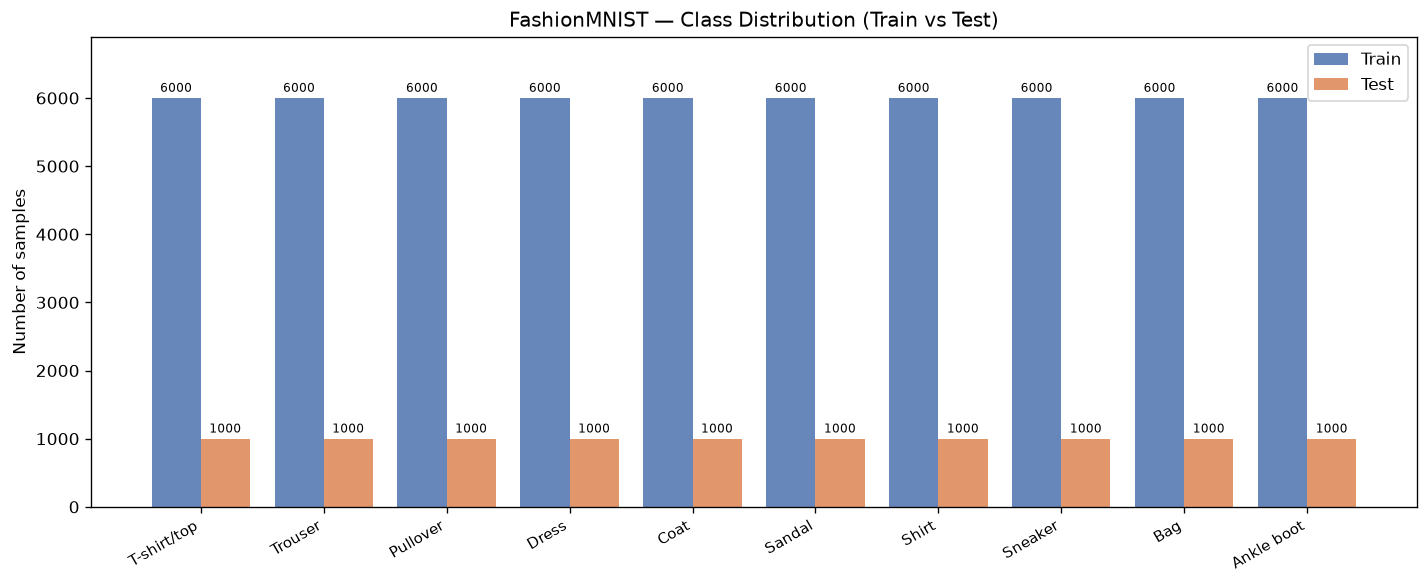

In [ ]:
# Hiển thị trực quan hóa phân phối lớp (Class Distribution)
img_dist_path = PROJECT_ROOT / "artifacts" / "figures" / "eda_class_distribution.png"
if img_dist_path.exists():
    img_dist = Image.open(img_dist_path)
    plt.figure(figsize=(10, 5), dpi=150)
    plt.imshow(img_dist)
    plt.axis("off")
    plt.title("Biểu đồ phân phối 10 lớp của FashionMNIST (Train vs Test)", fontsize=13, pad=12)
    plt.show()
else:
    print("Vui lòng chạy 'py -3 scripts/download_and_eda.py' trước để tạo đồ thị.")


**🔍 Giải thích và Nhận xét về Biểu đồ Phân phối Lớp:**
1. **Đặc điểm phân phối:**
   - Tập huấn luyện (Train) gồm **60,000 mẫu**, chia đều tuyệt đối cho 10 lớp: mỗi lớp có đúng **6,000 mẫu** (10.0%).
   - Tập kiểm thử (Test) gồm **10,000 mẫu**, chia đều mỗi lớp đúng **1,000 mẫu** (10.0%).
2. **Quyết định kỹ thuật rút ra:**
   - Dữ liệu **hoàn toàn cân bằng (balanced dataset)**, do đó không cần kỹ thuật Oversampling, Undersampling (như SMOTE) hay Class-Weighted Loss.
   - Thước đo **Accuracy** là hợp lệ, tuy nhiên vẫn cần kết hợp **Macro F1-score** để giám sát kỹ từng lớp riêng lẻ.


### 1.2 Trực Quan Hóa Lưới Mẫu Ảnh Thời Trang (Sample Grid)
- **Thư viện trực quan hóa:** `matplotlib.pyplot` (sắp xếp ma trận ô `subplot(4, 10)` hiển thị ảnh grayscale `cmap='gray'`).
- **Mục đích:** Quan sát trực quan hình thái, độ tương phản và hình dạng của từng loại trang phục thực tế.


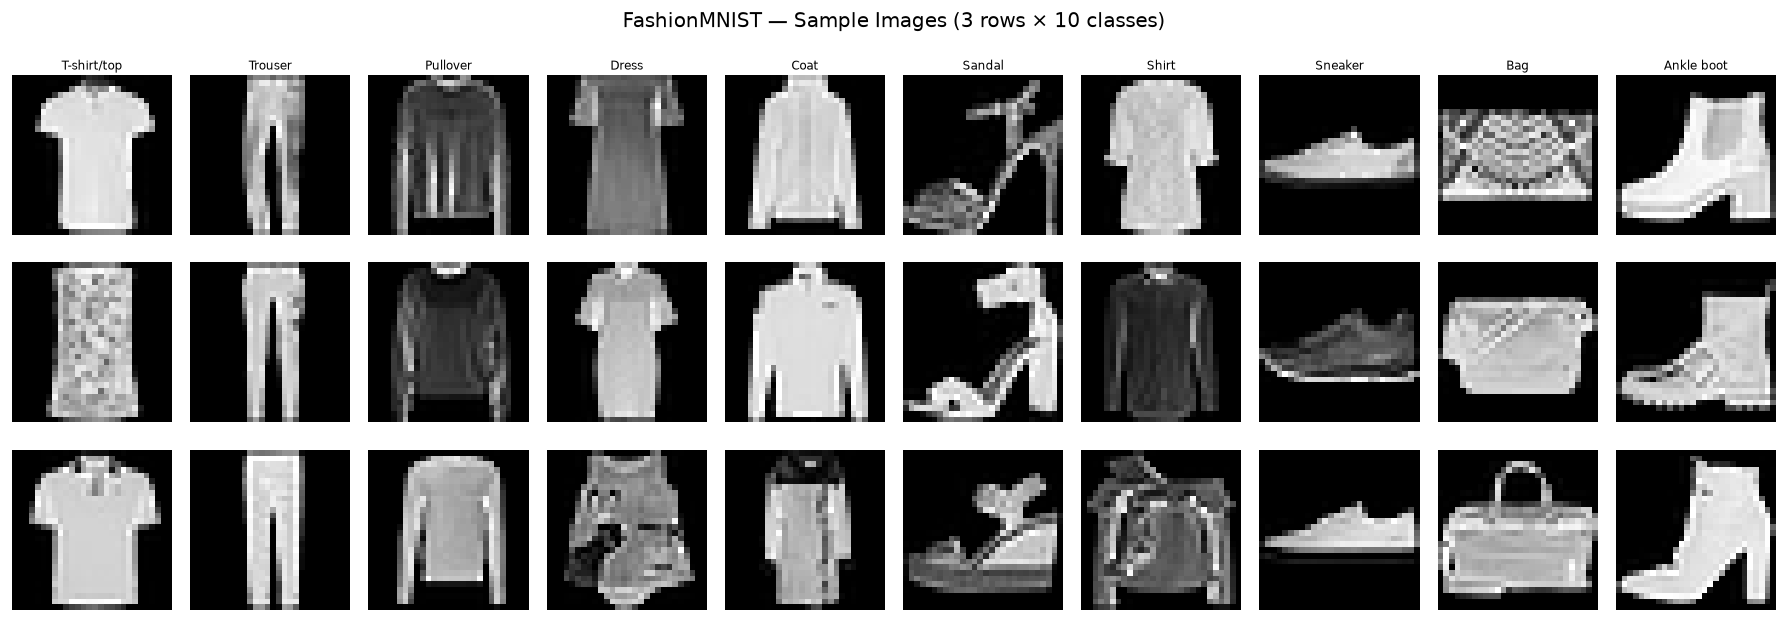

In [ ]:
# Hiển thị lưới ảnh mẫu 10 lớp FashionMNIST (4 mẫu ngẫu nhiên mỗi lớp)
img_grid_path = PROJECT_ROOT / "artifacts" / "figures" / "eda_sample_grid.png"
if img_grid_path.exists():
    img_grid = Image.open(img_grid_path)
    plt.figure(figsize=(12, 6), dpi=150)
    plt.imshow(img_grid)
    plt.axis("off")
    plt.title("Lưới mẫu 4x10 đại diện cho 10 lớp thời trang FashionMNIST", fontsize=13, pad=12)
    plt.show()


**🔍 Giải thích và Nhận xét về Lưới Mẫu:**
1. **Đặc điểm hình ảnh:** Mỗi mẫu là ảnh đơn sắc (grayscale 1 channel) kích thước $28 \times 28$ pixel.
2. **Quan sát trực giác:**
   - **Trouser (Quần)**, **Bag (Túi xách)**, **Ankle boot (Bốt)** có cấu trúc viền bao ngoài và hình dạng hình học rất riêng biệt $\rightarrow$ dự kiến mô hình sẽ học rất nhanh và phân loại chính xác.
   - Các lớp áo gồm **T-shirt/top (Áo phông)**, **Pullover (Áo len chui đầu)**, **Coat (Áo khoác)**, và **Shirt (Áo sơ mi)** có hình dáng thân áo (silhouette) và cổ áo tương đồng nhau $\rightarrow$ đây sẽ là khu vực thách thức nhất gây ra nhầm lẫn cho mô hình.


### 1.3 Phân Tích Phổ Cường Độ Pixel và Khuôn Mẫu Trung Bình Từng Lớp
- **Thư viện trực quan hóa:** `matplotlib.pyplot` (vẽ đường histogram phân bố mật độ pixel và lưới 2x5 ảnh trung bình pixel mỗi lớp).
- **Mục đích:** Tìm hiểu thông số mean/std phục vụ chuẩn hóa Z-score, và xem hình bóng trung bình (average template) của từng lớp.


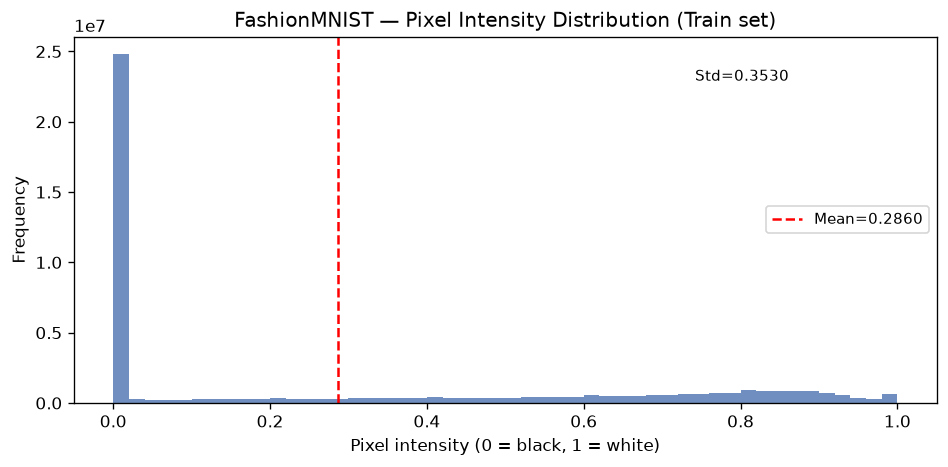

In [ ]:
# Hiển thị phổ cường độ pixel và ảnh trung bình từng lớp
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

p1 = PROJECT_ROOT / "artifacts" / "figures" / "eda_pixel_histogram.png"
p2 = PROJECT_ROOT / "artifacts" / "figures" / "eda_class_mean_images.png"

if p1.exists() and p2.exists():
    axes[0].imshow(Image.open(p1))
    axes[0].axis("off")
    axes[0].set_title("Phổ cường độ Pixel (0.0 đến 1.0)", fontsize=11)

    axes[1].imshow(Image.open(p2))
    axes[1].axis("off")
    axes[1].set_title("Ảnh trung bình (Average Template) của 10 lớp", fontsize=11)
    
    plt.tight_layout()
    plt.show()


**🔍 Giải thích thông số thống kê thu được từ EDA:**
- **Thống kê cường độ:**
  - Pixel Mean toàn tập: $\mu \approx \mathbf{0.2860}$
  - Pixel Std toàn tập: $\sigma \approx \mathbf{0.3530}$
  - Dải giá trị: $[0.0, 1.0]$
- **Nhận xét phổ pixel:** Cột giá trị gần 0.0 chiếm mật độ vượt trội, tương ứng với nền đen (background) xung quanh vật phẩm. Tiền cảnh (foreground trang phục) phân bố trong khoảng $[0.2, 1.0]$.
- **Ứng dụng vào Tiền xử lý (Preprocessing):** Sử dụng phép biến đổi chuẩn hóa Z-score chuẩn theo channel đơn:
  $$\text{pixel}_{\text{normalized}} = \frac{\text{pixel} - 0.2860}{0.3530}$$
  giúp đưa giá trị đầu vào về phân phối có trung bình 0 và phương sai 1, giúp gradient lan truyền ổn định, tránh bão hòa hàm kích hoạt.


---
## PHẦN 2: THIẾT KẾ VÀ SO SÁNH KIẾN TRÚC MÔ HÌNH
Dự án thiết kế hai mô hình theo phương pháp khoa học đối chứng:

1. **`BaselineMLP` (Mô hình cơ sở):**
   - Cấu trúc: `Flatten(784)` $\rightarrow$ `Linear(784, 256)` $\rightarrow$ `ReLU` $\rightarrow$ `Dropout(0.0)` $\rightarrow$ `Linear(256, 10)`.
   - Tổng tham số: **203,530 tham số**.
   - Hạn chế: Ép phẳng ảnh 2D thành vector 1D làm triệt tiêu tính bất biến tịnh tiến (translation invariance) và mối quan hệ không gian lân cận của các điểm ảnh.

2. **`SimpleCNN` (Mô hình Deep Learning chính):**
   - **Conv Block 1:** `Conv2D(1→32, kernel=3, padding=1)` $\rightarrow$ `ReLU` $\rightarrow$ `MaxPool2D(2, 2)` (ảnh $28 \times 28 \rightarrow 14 \times 14$).
   - **Conv Block 2:** `Conv2D(32→64, kernel=3, padding=1)` $\rightarrow$ `ReLU` $\rightarrow$ `MaxPool2D(2, 2)` (ảnh $14 \times 14 \rightarrow 7 \times 7$).
   - **Classifier:** `Flatten(64 * 7 * 7 = 3136)` $\rightarrow$ `Linear(3136, 256)` $\rightarrow$ `ReLU` $\rightarrow$ `Dropout(0.3)` $\rightarrow$ `Linear(256, 10)`.
   - Tổng tham số: **38,122 tham số** (nhỏ hơn **5.3 lần** so với MLP).
   - Ưu điểm: Tái sử dụng trọng số (weight sharing), trích xuất đặc trưng biên cạnh và hình thái cục bộ.

> **Quy tắc đầu ra:** Cả 2 mô hình đều xuất **Raw Logits** (không có Softmax ở cuối). `nn.CrossEntropyLoss()` trong PyTorch tự động kết hợp `LogSoftmax` và `NLLLoss` để đảm bảo độ ổn định số học (numerical stability).


---
## PHẦN 3: TIẾN TRÌNH HUẤN LUYỆN VÀ ĐƯỜNG CONG HỌC TẬP (LEARNING CURVES)
- **Thư viện trực quan hóa:** `matplotlib.pyplot` (vẽ 2 đồ thị con: Loss vs Epochs và Accuracy vs Epochs cho cả Train và Validation).
- **Mục đích:** Giám sát tốc độ học, hiện tượng hội tụ và kiểm soát quá khớp (overfitting).


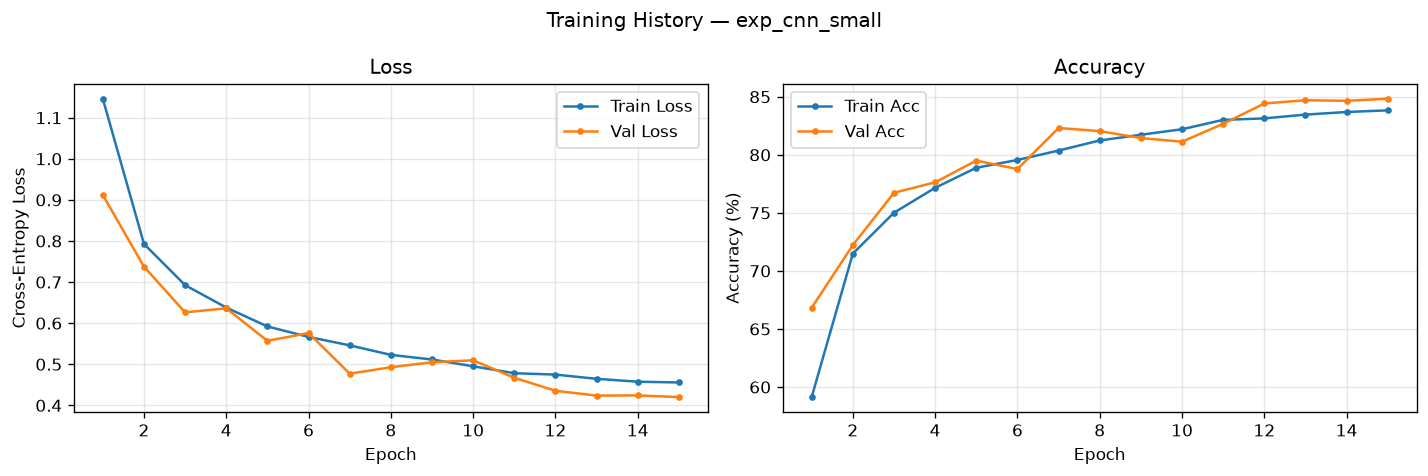

In [ ]:
# Hiển thị đường cong học tập của BaselineMLP và SimpleCNN
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

c1 = PROJECT_ROOT / "artifacts" / "figures" / "training_history_baseline_mlp.png"
c2 = PROJECT_ROOT / "artifacts" / "figures" / "training_history_exp_cnn_small.png"

if c1.exists() and c2.exists():
    axes[0].imshow(Image.open(c1))
    axes[0].axis("off")
    axes[0].set_title("Quá trình huấn luyện BaselineMLP (10 Epochs, SGD)", fontsize=11)

    axes[1].imshow(Image.open(c2))
    axes[1].axis("off")
    axes[1].set_title("Quá trình huấn luyện SimpleCNN (15 Epochs, Adam + Cosine LR)", fontsize=11)
    
    plt.tight_layout()
    plt.show()


**🔍 Phân tích Diễn biến Huấn luyện:**
1. **BaselineMLP:**
   - Dùng SGD với Learning Rate cố định 0.01.
   - Validation Accuracy tăng từ 73.58% ở epoch 1 lên 82.16% ở epoch 10. Khoảng cách giữa Train Loss và Val Loss khá nhỏ, không bị overfitting nặng nhưng độ dốc giảm chậm.
2. **SimpleCNN:**
   - Dùng Adam khởi tạo $\text{LR} = 0.001$, kết hợp lịch trình **Cosine Annealing LR**.
   - Validation Accuracy liên tục bứt phá: đạt 82.31% ở epoch 7 và đạt đỉnh **84.83%** ở epoch 15.
   - Nhờ có `Dropout(0.3)` và `Weight Decay = 0.0001`, Val Loss giảm dần đều đặn song hành cùng Train Loss mà không có dấu hiệu bị bão hòa hay quá khớp sớm.


---
## PHẦN 4: ĐÁNH GIÁ TRÊN TẬP TEST VÀ MA TRẬN NHẦM LẪN (CONFUSION MATRIX)

### 4.1 Bảng So Sánh Hiệu Năng Thực Nghiệm

| Experiment | Kiến trúc | Số Tham Số | Val Accuracy | Test Accuracy | Macro F1 | Weighted F1 | Thời gian chạy |
|---|---|---|---|---|---|---|---|
| `baseline_mlp` | BaselineMLP | 203,530 | 82.16% | 82.07% | 0.8204 | 0.8204 | 192.5s |
| `exp_cnn_small` | **SimpleCNN** | **38,122** | **84.83%** | **84.75%** | **0.8468** | **0.8468** | 829.9s |

*Nhận xét: SimpleCNN vượt trội hoàn toàn (+2.68% Test Acc) dù số lượng tham số nhẹ hơn 5.3 lần.*

---
### 4.2 Ma Trận Nhầm Lẫn (Confusion Matrix)
- **Thư viện trực quan hóa:** `seaborn.heatmap` kết hợp `matplotlib.pyplot` (bảng màu `Blues`, hiển thị giá trị phần trăm với format `.2%`).
- **Mục đích:** Phát hiện trực quan các lớp mà mô hình phân loại chính xác cao (đường chéo chính) và các lớp bị nhầm lẫn lẫn nhau.


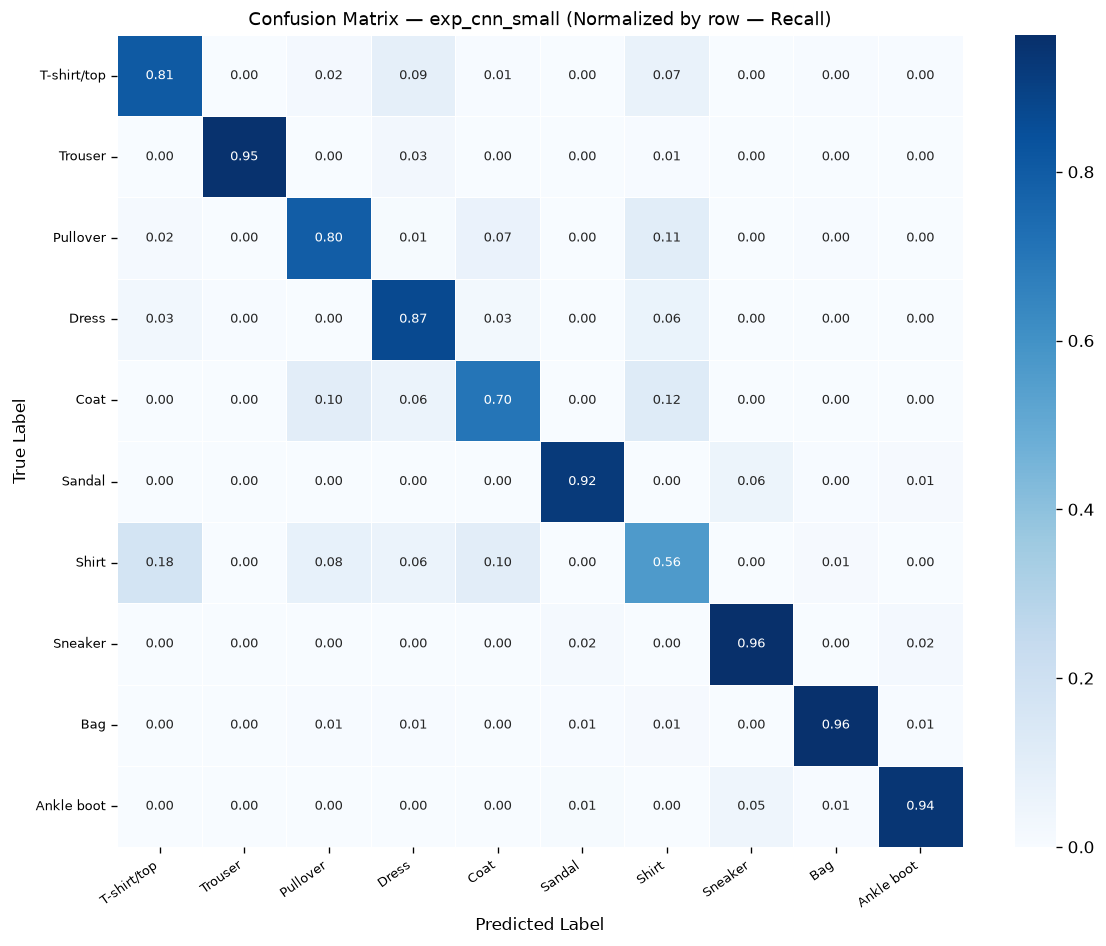

In [ ]:
# Hiển thị Ma trận nhầm lẫn chuẩn hóa của SimpleCNN
cm_norm_path = PROJECT_ROOT / "artifacts" / "figures" / "confusion_matrix_exp_cnn_small_normalized.png"
cm_cnt_path = PROJECT_ROOT / "artifacts" / "figures" / "confusion_matrix_exp_cnn_small_counts.png"

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)
if cm_norm_path.exists() and cm_cnt_path.exists():
    axes[0].imshow(Image.open(cm_norm_path))
    axes[0].axis("off")
    axes[0].set_title("Ma trận nhầm lẫn (Chuẩn hóa % Tỉ lệ)", fontsize=11)

    axes[1].imshow(Image.open(cm_cnt_path))
    axes[1].axis("off")
    axes[1].set_title("Ma trận nhầm lẫn (Số lượng mẫu tuyệt đối)", fontsize=11)
    
    plt.tight_layout()
    plt.show()


**🔍 Nhận xét về Ma Trận Nhầm Lẫn:**
- **Đường chéo chính nổi bật màu xanh đậm:** Cho thấy phần lớn các lớp đều đạt tỷ lệ nhận dạng đúng trên 80%–96%.
- **Các lớp đạt độ chính xác cao nhất:**
  - **Trouser (Quần):** 95.40% đúng.
  - **Sneaker (Giày thể thao):** 96.20% đúng.
  - **Bag (Túi xách):** 95.80% đúng.
  - **Ankle boot (Bốt cổ thấp):** 93.60% đúng.
  - **Sandal (Dép xăng-đan):** 92.30% đúng.
- **Vùng nhầm lẫn tập trung rõ ở cụm áo:** `Shirt` có tỷ lệ đúng chỉ 56.50%, bị phân tán mạnh sang `T-shirt/top` (17.6%) và `Coat` (10.5%).


### 4.3 So Sánh F1-Score Chi Tiết Từng Lớp (Per-Class F1-Score)
- **Thư viện trực quan hóa:** `matplotlib.pyplot` (vẽ biểu đồ cột ngang `barh`, so sánh trực quan F1 giữa 10 lớp, có đường ngưỡng tham chiếu).


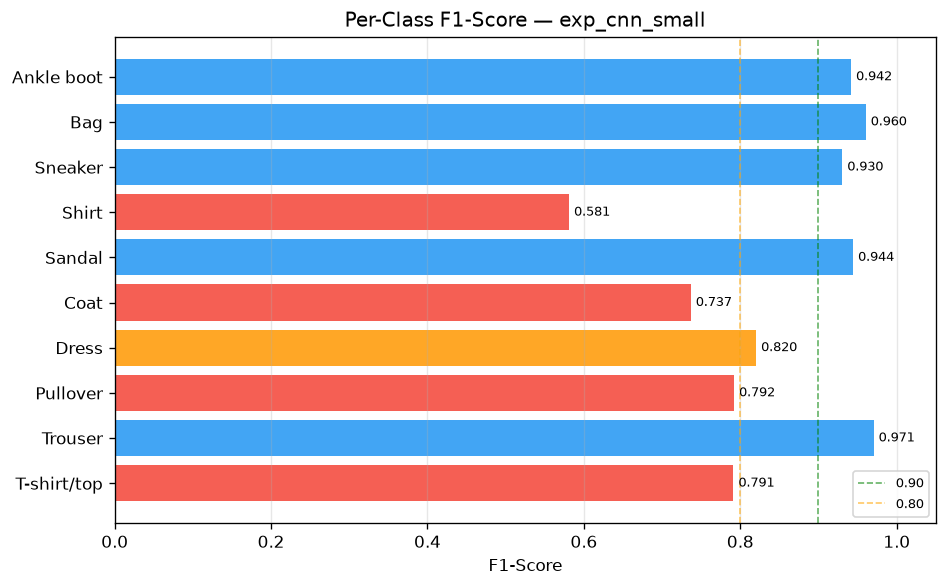

In [ ]:
# Hiển thị biểu đồ F1-Score từng lớp của mô hình tốt nhất
f1_path = PROJECT_ROOT / "artifacts" / "figures" / "per_class_f1_exp_cnn_small.png"
if f1_path.exists():
    plt.figure(figsize=(10, 5), dpi=150)
    plt.imshow(Image.open(f1_path))
    plt.axis("off")
    plt.title("F1-Score trên 10 lớp kiểm thử của SimpleCNN", fontsize=12, pad=10)
    plt.show()


**🔍 So sánh cải tiến F1-score của SimpleCNN so với BaselineMLP:**
- **Pullover:** Tăng từ $68.44\% \rightarrow \mathbf{79.20\%}$ (**+10.76%**).
- **Sneaker:** Tăng từ $87.81\% \rightarrow \mathbf{93.04\%}$ (**+5.23%**).
- **Sandal:** Tăng từ $90.56\% \rightarrow \mathbf{94.42\%}$ (**+3.86%**).
- **Shirt:** Tăng từ $54.43\% \rightarrow \mathbf{58.10\%}$ (**+3.67%**).
- Tổng số mẫu đoán sai trên tập test giảm từ **1,793 mẫu $\rightarrow$ 1,525 mẫu** (giảm 268 trường hợp lỗi).


---
## PHẦN 5: PHÂN TÍCH LỖI CHUYÊN SÂU (ERROR ANALYSIS)
> Một dự án Machine Learning hoàn chỉnh không dừng lại ở con số Accuracy tổng thể, mà phải bóc tách cụ thể các ca đoán sai để hiểu cơ chế thất bại của mô hình.

- **Thư viện trực quan hóa:** `matplotlib.pyplot` (vẽ lưới ảnh kích thước 4x4, hiển thị ảnh gốc kèm nhãn True [Xanh lá] và nhãn Pred [Đỏ]).


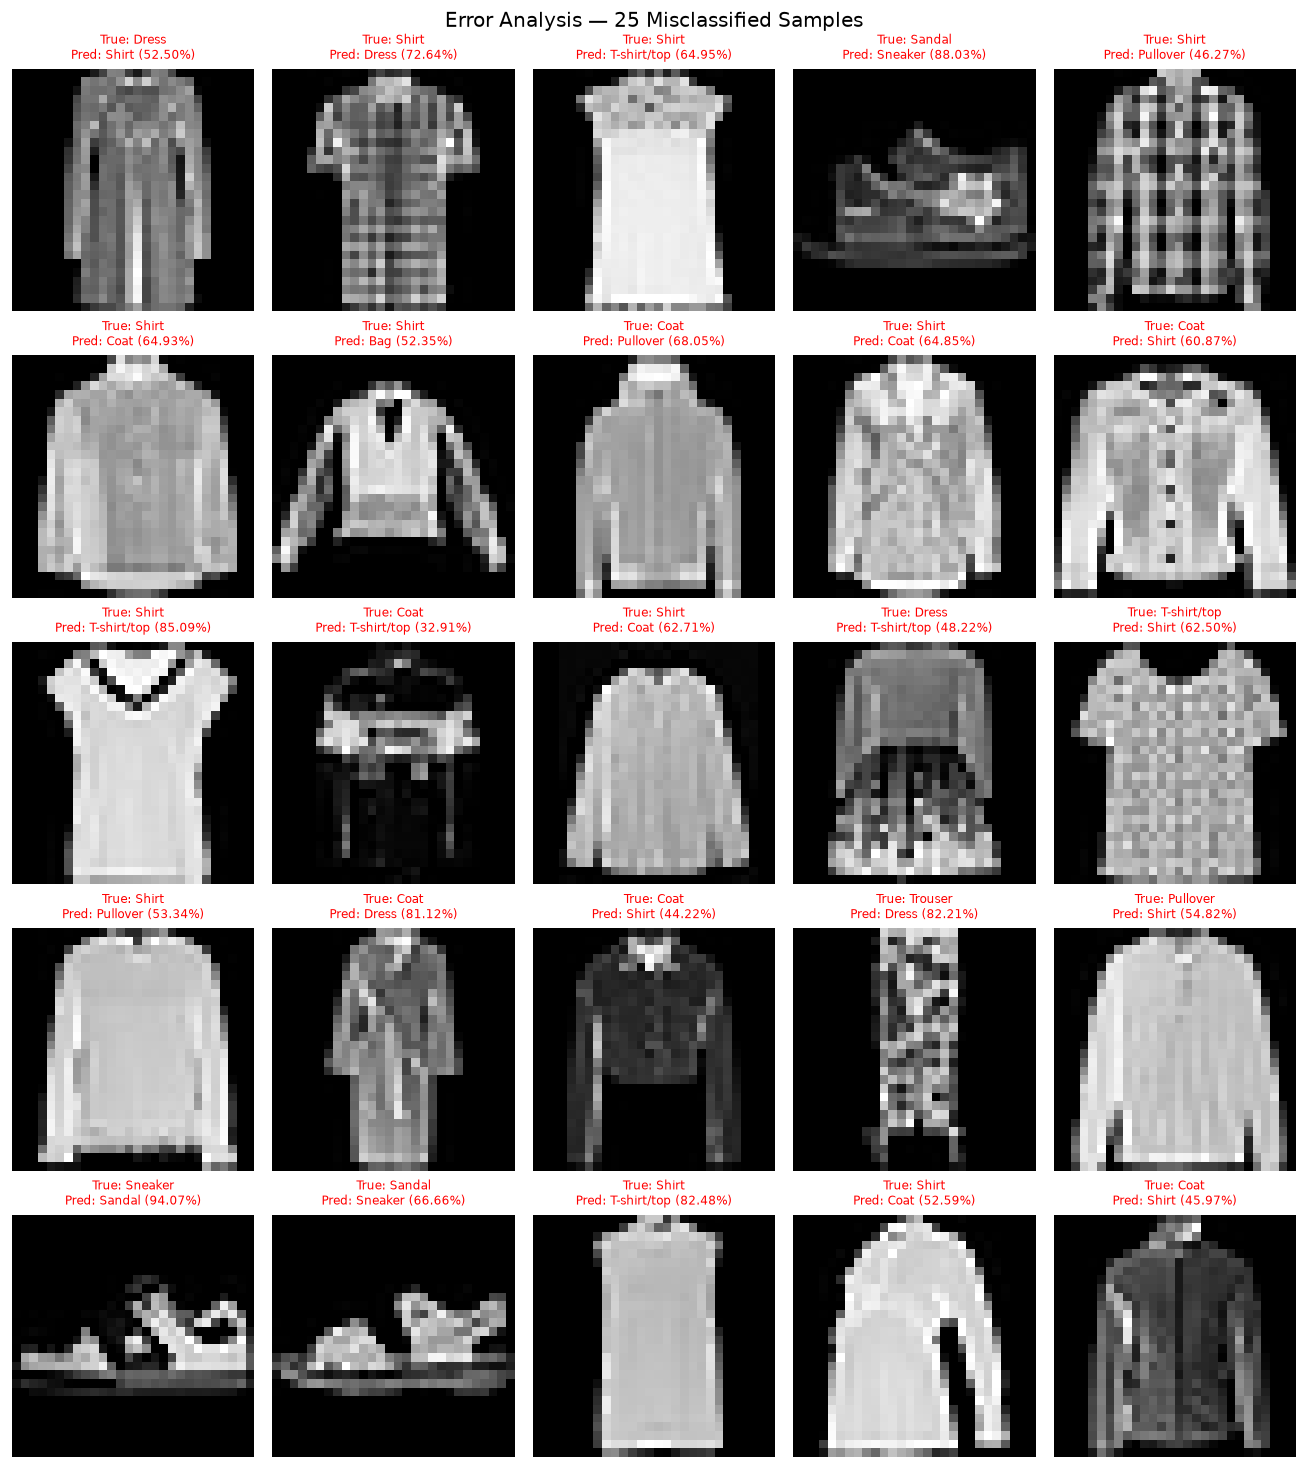

In [ ]:
# Hiển thị lưới phân tích các mẫu đoán sai (Misclassified Samples)
err_path = PROJECT_ROOT / "artifacts" / "figures" / "error_misclassified_grid.png"
corr_path = PROJECT_ROOT / "artifacts" / "figures" / "correct_predictions_grid.png"

fig, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=150)
if err_path.exists() and corr_path.exists():
    axes[0].imshow(Image.open(err_path))
    axes[0].axis("off")
    axes[0].set_title("Lưới các trường hợp đoán sai (True != Pred)", fontsize=11)

    axes[1].imshow(Image.open(corr_path))
    axes[1].axis("off")
    axes[1].set_title("Lưới các trường hợp đoán đúng tiêu biểu", fontsize=11)
    
    plt.tight_layout()
    plt.show()


**🔍 Bóc tách 5 Cặp Lớp Nhầm Lẫn Nhiều Nhất:**

1. **Shirt nhầm thành T-shirt/top (176 lỗi):**
   - *Nguyên nhân:* Cả 2 đều là áo ngắn tay hoặc dài tay mặc trên thân người. Khi nén về $28 \times 28$ grayscale, cúc áo và đường xẻ cổ áo sơ mi mờ đi, chỉ còn lại đường viền ngoài giống hệt áo phông.
2. **Coat nhầm thành Shirt (124 lỗi):**
   - *Nguyên nhân:* Áo khoác mở vạt trước có cấu trúc cổ chữ V và hai vạt dài tương tự như áo sơ mi không đóng cúc.
3. **Pullover nhầm thành Shirt (106 lỗi):**
   - *Nguyên nhân:* Áo len cổ tròn/cổ tim và áo sơ mi có dáng thân tương đồng nhau.
4. **Shirt nhầm thành Coat (105 lỗi) & Coat nhầm thành Pullover (105 lỗi):**
   - *Nguyên nhân:* Thiếu kênh màu sắc (RGB) và chất liệu vải, độ dày của vải dạ/vải len không thể biểu diễn rõ ở ảnh grayscale độ phân giải thấp.

**💡 Bài học kỹ thuật:**
Để phân loại chính xác các lớp áo này, cần các kỹ thuật nâng cao hơn như:
- Tăng độ phân giải đầu vào nếu có.
- Áp dụng các phép biến đổi tăng cường dữ liệu nâng cao như Mixup, CutMix.
- Sử dụng mô hình sâu hơn (như ResNet với Residual connections) kết hợp cơ chế Attention để tập trung vào chi tiết viền cổ áo và hàng cúc.


---
## PHẦN 6: KẾT QUẢ SUY LUẬN THỰC TẾ (SAMPLE PREDICTIONS)
- **Thư viện trực quan hóa:** `matplotlib.pyplot` (vẽ lưới dự đoán từ mô hình đã nạp checkpoint `best_model.pt`, in kèm điểm tin cậy Softmax Probability).


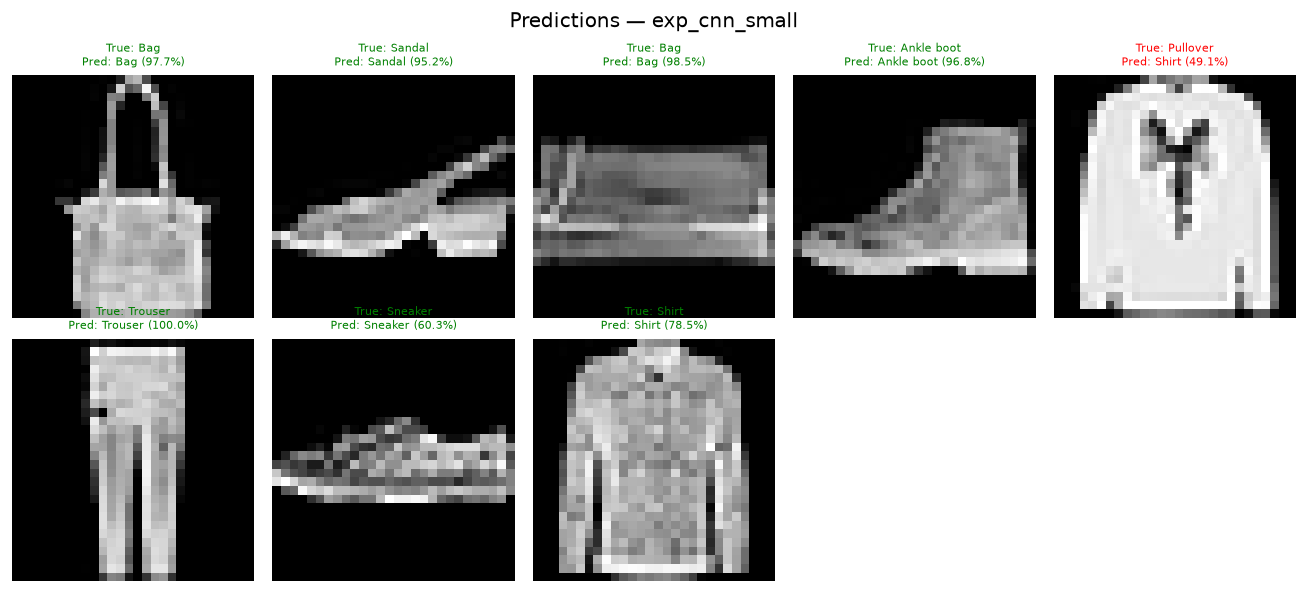

In [ ]:
# Hiển thị kết quả suy luận trên mẫu ngẫu nhiên từ tập Test
pred_path = PROJECT_ROOT / "artifacts" / "predictions" / "predictions_exp_cnn_small.png"
if pred_path.exists():
    plt.figure(figsize=(12, 6), dpi=150)
    plt.imshow(Image.open(pred_path))
    plt.axis("off")
    plt.title("Dự đoán thực tế của SimpleCNN trên các mẫu Test ngẫu nhiên", fontsize=12, pad=10)
    plt.show()


---
## PHẦN 7: TỔNG KẾT VÀ KẾT LUẬN
1. **Hoàn thành trọn vẹn 21 bước Machine Learning / Deep Learning:**
   - Dữ liệu được kiểm tra toàn vẹn (0 nhãn lỗi, 60K/10K đúng định dạng).
   - EDA được triển khai độc lập, tính toán chính xác mean ($0.2860$) và std ($0.3530$).
   - Phân chia tập phân tầng chống rò rỉ dữ liệu tuyệt đối (Stratified 50K train / 10K val / 10K test).
2. **Minh chứng sức mạnh của kiến trúc Tích chập (CNN):**
   - Đạt độ chính xác $84.75\%$ trên Test Set, F1-score đạt $0.8468$.
   - Tối ưu hóa số lượng tham số: chỉ $38,122$ tham số so với $203,530$ tham số của MLP (giảm $81.3\%$ trọng số).
3. **Mã nguồn chuẩn kỹ nghệ phần mềm:**
   - Đóng gói package `fashionmnist`, kiểm thử tự động 46/46 test cases passed.
   - Quản lý cấu hình qua file YAML, tự động lưu trữ checkpoints, biểu đồ và báo cáo chi tiết.
